# Baseline verification and learning gate

Baseline verification pre-Q1.

`exp.run_sanity_checks()` executes five groups of lightweight tests, covering:
* Parameter shapes, recurrence consistency and gate recording.
* Gate interventions and identity controls.
* Gradient propagation.
* Analytical and numerical Jacobian consistency.
* Representation-probe calibration and paired-initialisation controls.

The cell additionally verifies the theoretical mean squared error of the optimal length-only predictor:

$$
R_{\mathrm{length}}
=\mathbb E[T/4]
=3.125.
$$

For the optimal constant predictor,

$$
R_{\mathrm{constant}}
=\operatorname{Var}(Y)
=8.4375.
$$

In [8]:
%cd /content

import counting_experiment as exp
print("Import successful!")

/content
Import successful!


In [9]:
import math
import torch
import matplotlib.pyplot as plt
import counting_experiment as exp

# Configuration is frozen before evaluating a trained model.
P = 0.5
ID_LENGTHS = tuple(range(5, 21))
UPDATES = 10_000
B_ID = 1_024
MODEL_SEED, TRAIN_SEED, VAL_SEED = 42, 43, 44
ID_EVALUATION_SEED = 1001
EXACT_COUNT_SEED = 1003
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f'PyTorch={torch.__version__}; device={DEVICE}')
print('Sanity checks:', exp.run_sanity_checks())
assert abs(sum(T / 4 for T in ID_LENGTHS) / len(ID_LENGTHS) - 3.125) < 1e-12
assert abs(3.125 + 21.25 / 4 - 8.4375) < 1e-12
print('Analytical reference risks verified: length-only=3.125, constant=8.4375.')

PyTorch=2.14.1+cu130; device=cuda
Sanity checks: {'check_shapes_and_recording': 'passed', 'check_interventions': 'passed', 'check_gradient_propagation': 'passed', 'check_jacobian': 'passed', 'check_methodological_revisions': 'passed'}
Analytical reference risks verified: length-only=3.125, constant=8.4375.


## Baseline training
The function `train_counting()` constructs a `CountingGRUSystem` comprising a 16-unit scratch GRU and a scalar affine readout.

At every optimiser update:
* 1. Sample a sequence length uniformly from $T=5,\ldots,20$.
* 2. Generate a batch of 64 independent $Bernoulli(0.5)$ binary sequences.
* 3. Construct each final-count target by summing its tokens.
* 4. Calculate the scalar prediction from the final hidden state.
* 5. Compute final-count MSE.
* 6. Backpropagate and update all trainable parameters using Adam with learning rate $10^{-3}$.

Only the final count is supervised. Intermediate cumulative counts are not used in the loss.

A fixed, independently generated validation collection contains 256 sequences at each training length.

At intervals of 100 updates, the function records:
* `train_mse`: mean minibatch training MSE over the preceding logging interval, during which model parameters are changing.
* `val_mse`: MSE on the fixed ID validation collection using the current model parameters.

The training data are freshly sampled, rather than drawn from a fixed finite training dataset.

The experiment uses the model returned after the final update. No validation-selected checkpoint is substituted.



In [10]:
model, training_history = exp.train_counting(
    updates=UPDATES,
    seed=MODEL_SEED,
    data_seed=TRAIN_SEED,
    val_seed=VAL_SEED,
    p=P,
    device=DEVICE,
    batch_size=64,
    lr=1e-3,
    log_every=100,
)
print('Training completed; final logged validation MSE:', training_history[-1]['val_mse'])

{'update': 100, 'train_mse': 33.09964977741242, 'val_mse': 16.0607967376709}
{'update': 200, 'train_mse': 10.775276792645455, 'val_mse': 8.950458526611328}
{'update': 300, 'train_mse': 7.136454226374626, 'val_mse': 6.672950744628906}
{'update': 400, 'train_mse': 6.080315309464932, 'val_mse': 4.920269966125488}
{'update': 500, 'train_mse': 4.236360068619251, 'val_mse': 3.7337121963500977}
{'update': 600, 'train_mse': 3.0817884784936904, 'val_mse': 3.0714635848999023}
{'update': 700, 'train_mse': 2.8791077308356763, 'val_mse': 2.428374767303467}
{'update': 800, 'train_mse': 1.7956976149976254, 'val_mse': 2.0277087688446045}
{'update': 900, 'train_mse': 1.738476957976818, 'val_mse': 1.816444754600525}
{'update': 1000, 'train_mse': 1.5795182754844428, 'val_mse': 1.5359523296356201}
{'update': 1100, 'train_mse': 1.516847310513258, 'val_mse': 1.1993905305862427}
{'update': 1200, 'train_mse': 1.5309943466633558, 'val_mse': 0.9791629314422607}
{'update': 1300, 'train_mse': 0.6731249966844917, 

## Functional learning assessment
`exp.length_batches()` generates independent $Bernoulli(0.5)$ sequences for every length $T=5,\ldots,20$, using evaluation seed 1001.

Each length contributes 1,024 sequences, giving

$$
N=16\times1024=16{,}384
$$

held-out evaluation examples.

Because sample sizes are equal across lengths, the pooled empirical risk estimates risk under the intended uniform length distribution.

`exp.evaluate_predictive()` evaluates the trained model and the length-only reference on the same examples.

For each sequence length, it reports:
* MSE.
* MAE.
* Signed prediction bias.
* Rounded exact-count accuracy.
* Corresponding $pT$ reference metrics.

`exp.check_id_learning()` evaluates the prespecified pooled accuracy threshold of 95% and separately reports the worst per-length accuracy.

In [11]:
id_batches = exp.length_batches(
    ID_LENGTHS, batch_size=B_ID, p=P,
    device=DEVICE, seed=ID_EVALUATION_SEED,
)
id_report = exp.evaluate_predictive(model, id_batches, p=P)
id_gate = exp.check_id_learning(id_report, minimum_accuracy=0.95)

print(id_gate['message'])
print('T    n    GRU_MSE  pT_MSE  GRU_MAE  accuracy    bias')
for T in ID_LENGTHS:
    row = id_report[T]
    m, ref = row['model'], row['length_only_pT']
    print(f"{T:2d} {m['n']:5d} {m['mse']:9.4f} {ref['mse']:7.4f} "
          f"{m['mae']:8.4f} {m['rounded_accuracy']:8.3f} {m['bias']:8.4f}")

if not id_gate['passed']:
    print('Interpretive restriction: Q1 remains exploratory for this partially learned model.')
print('Minimum per-length rounded accuracy:', round(id_gate['minimum_per_length_accuracy'], 4))

Pooled ID rounded accuracy 0.997; minimum per-length accuracy 0.970; pooled threshold 0.950: PASS.
T    n    GRU_MSE  pT_MSE  GRU_MAE  accuracy    bias
 5  1024    0.0170  1.3105   0.0951    1.000   0.0948
 6  1024    0.0099  1.4990   0.0623    1.000   0.0581
 7  1024    0.0071  1.8203   0.0487    1.000   0.0335
 8  1024    0.0039  1.9482   0.0387    1.000   0.0065
 9  1024    0.0043  2.2891   0.0426    1.000  -0.0045
10  1024    0.0030  2.4502   0.0432    1.000  -0.0159
11  1024    0.0031  2.6367   0.0470    1.000  -0.0193
12  1024    0.0039  2.9727   0.0531    1.000  -0.0161
13  1024    0.0039  3.0195   0.0531    1.000  -0.0094
14  1024    0.0048  3.3203   0.0585    1.000   0.0017
15  1024    0.0054  3.7246   0.0615    1.000   0.0080
16  1024    0.0059  3.7881   0.0655    1.000   0.0194
17  1024    0.0076  4.0391   0.0705    0.998   0.0220
18  1024    0.0124  4.4971   0.0802    0.993   0.0183
19  1024    0.0206  4.5371   0.0901    0.986   0.0071
20  1024    0.0310  4.7119   0.1069   

The observed pooled rounded-count accuracy is approximately

$$
\boxed{A_{\mathrm{ID}}=0.9967.}
$$

The minimum per-length accuracy is

$$
\boxed{A_{\min}=0.9697,}
$$

occurring at $T=20$.

The functional ID learning gate therefore reports PASS.

The pooled GRU MSE is approximately 0.00899, compared with approximately 3.0353 for the length-only reference on the same evaluation examples.

Thus the estimated reduction in squared prediction error relative to the length-only predictor is

$$
\Delta\widehat R
\approx3.0353-0.0090
=3.0263.
$$

This corresponds to a reduction of approximately 99.7% in empirical MSE relative to that reference.

The deterioration is worth recording. \
The learned predictor is not uniformly error-free across the training interval. \
Signed bias is relatively small across the length range, with no sustained large undercounting pattern in the reported ID results.

# Visualisation
Plot both series against optimiser update, allowing the development of training error and fixed-distribution validation error to be compared over the complete optimisation trajectory.

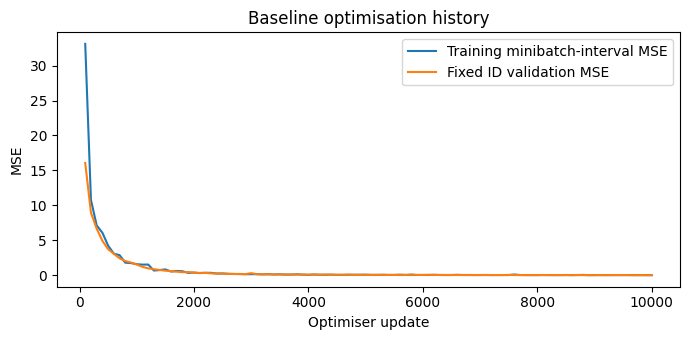

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([r['update'] for r in training_history],
        [r['train_mse'] for r in training_history], label='Training minibatch-interval MSE')
ax.plot([r['update'] for r in training_history],
        [r['val_mse'] for r in training_history], label='Fixed ID validation MSE')
ax.set(xlabel='Optimiser update', ylabel='MSE', title='Baseline optimisation history')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


The figure shows a steep initial reduction in loss, followed by progressively smaller improvements, as expected.

Both training and validation error become substantially lower after the first several thousand updates. \
Short-lived increases remain visible in the validation series. These fluctuations do not prevent the overall downward trend. \
By update 10,000, validation MSE reaches approximately 0.0107.